In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import bisect
import math

from scipy.stats import norm
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Sampler

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pd.set_option("display.max_columns", 100)


In [2]:
# Update paths/columns for the provided Optiver dataset
DATA_PATH = Path(r"shared-nvme/AFT/selected_features_top100_new.parquet")
EXTRA_PATH = Path(r"train.csv")
ID_COL = "stock_id"
ORDER_COLS = ["date_id", "seconds_in_bucket"]  # sort order within each stock
TARGET_COL = "target"

# Base dataset
df = pd.read_parquet(DATA_PATH)

# Merge any additional columns from train.csv that are not already present
extra_df = pd.read_csv(EXTRA_PATH)
if len(extra_df) != len(df):
    raise ValueError(f"Row count mismatch between parquet ({len(df)}) and train.csv ({len(extra_df)})")
new_cols = [c for c in extra_df.columns if c not in df.columns and c != 'row_id']
if new_cols:
    key_cols = ["stock_id", "date_id", "seconds_in_bucket"]
    df = df.merge(extra_df[key_cols + new_cols], on=key_cols, how="left", validate="one_to_one")
    print(f"Merged extra columns: {new_cols}")
else:
    print("No new columns to merge from train.csv")

display(df.head())
display(df.describe(include="all"))

Merged extra columns: ['imbalance_size', 'bid_price', 'bid_size', 'ask_price', 'ask_size', 'wap', 'time_id']


,stock_id,date_id,seconds_in_bucket,cs_cross_imb1_reference_price_ask_price_market_urgency_v3,market_urgency_v3,cs_cross_price_to_depth_ask_market_urgency_v3,cs_cross_imb1_reference_price_bid_price_market_urgency_v3,ts_diff_relative_signed_imbalance_1,ts_rolling_rank_ref_price_position_20,ts_bb_pct_signed_imbalance_20,cs_zscore_add_wap_trend_mock_ratio_3_wap_trend_macd_dif_imb1_reference_price_wap_3_6,ts_rolling_rank_signed_imbalance_20,cs_zscore_add_relative_signed_imbalance_imb1_reference_price_wap,ts_macd_hist_wap_trend_mock_1,ts_diff_near_price_1,cs_cross_price_to_depth_bid_notional_imbalance,ts_bb_pct_far_mid_deviation_20,cs_zscore_add_signed_imbalance_relative_signed_imbalance,ts_macd_wap_trend_mock_1,ts_diff_wap_trend_macd_dif_mid_price_near_far_6_12_1,cs_zscore_add_market_urgency_v3_wap_trend_mock_ratio_3,cs_divide_imb1_reference_price_wap_ref_price_position,cs_zscore_add_imb1_reference_price_ask_price_imb1_far_price_wap,far_price,ts_diff_wap_trend_log_return_5_5,cs_zscore_add_composite_pressure_wap_trend_ratio_10_30,cs_dev_mean_wap_trend_ratio_10_30,relative_signed_imbalance,ts_diff_ref_price_mid_deviation_5,cs_zscore_add_wap_trend_ratio_10_30_wap_trend_log_return_5,cs_zscore_add_near_mid_deviation_far_mid_deviation,ts_rolling_rank_imb1_far_price_wap_20,cs_zscore_add_signed_imbalance_imb1_reference_price_wap,cs_cross_imb1_reference_price_ask_price_wap_trend_mock_1,ts_bb_pct_wap_trend_ewm_12_imb1_reference_price_wap_20,cs_zscore_add_imb1_reference_price_bid_price_imb1_far_price_wap,cs_zscore_add_notional_imbalance_sell_dominance,ts_bb_pct_imb1_reference_price_wap_20,cs_zscore_add_market_urgency_v3_wap_trend_macd_dif_imb1_reference_price_wap_3_6,ts_ema_price_to_depth_ask_5,wap_trend_mock_ratio_1,cs_zscore_add_reference_price_wap,cs_cross_price_to_depth_ask_notional_imbalance,ts_ema_price_to_depth_bid_5,wap_trend_mock_ratio_3,ts_diff_near_mid_deviation_10,cs_cross_sell_dominance_wap_trend_ewm_12_imb1_reference_price_wap,ts_diff_imb1_reference_price_wap_1,cs_zscore_add_imbalance_buy_sell_flag_notional_imbalance,cs_cross_imb1_reference_price_ask_price_wap_trend_ewm_12_imb1_reference_price_wap,...,ts_diff_wap_trend_mock_3_5,cs_divide_price_to_depth_ask_buy_dominance,ts_diff_relative_signed_imbalance_10,ts_bb_pct_l1_bid_ask_size_ratio_20,cs_zscore_add_wap_trend_mock_3_wap_trend_macd_near_price_3_6,cs_zscore_add_wap_trend_zscore_15_reference_price_trend_20,reference_price,matched_size,ts_diff_imb1_reference_price_wap_10,ts_rsi_wap_trend_mock_1_14,cs_cross_imb1_reference_price_bid_price_wap_trend_macd_dif_imb1_reference_price_wap_3_6,cs_cross_imb1_reference_price_ask_price_wap_trend_mock_3,ts_diff_wap_trend_slope_20_1,cs_cross_buy_dominance_wap_trend_ewm_12_imb1_reference_price_wap,cs_cross_imb1_reference_price_bid_price_wap_trend_ewm_12_imb1_reference_price_wap,cs_cross_imbalance_size_wap_trend_ewm_12_imb1_reference_price_wap,ts_macd_hist_market_urgency_v3,ts_diff_reference_price_trend_20_5,wap_trend_macd_dif_near_price_3_6,imb1_reference_price_bid_price,ts_rolling_rank_far_mid_deviation_20,cs_cross_imb1_reference_price_bid_price_wap_trend_macd_near_price_3_6,cs_cross_notional_imbalance_ref_price_position,ts_bb_ma_wap_trend_macd_imb1_reference_price_wap_3_6_20,ts_rsi_wap_trend_log_return_10_14,cs_cross_far_price_wap_trend_macd_dif_near_price_3_6,ts_diff_imb1_reference_price_wap_5,ts_bb_pct_ref_price_mid_deviation_20,cs_zscore_add_wap_trend_mock_ratio_1_wap_trend_ewm_12_imb1_reference_price_wap,ts_diff_imb1_far_price_wap_1,imbalance_buy_sell_flag,cs_zscore_add_wap_trend_ewm_12_imb1_reference_price_wap_wap_trend_ewm_48_imb1_reference_price_wap,ts_bb_lower_reference_price_trend_20_20,cs_zscore_add_l1_bid_ask_size_ratio_sell_dominance,ts_macd_hist_l1_bid_ask_size_ratio,ts_rsi_wap_trend_zscore_15_14,cs_cross_sell_dominance_wap_trend_macd_dif_imb1_reference_price_wap_3_6,cs_divide_price_to_depth_bid_buy_dominance,cs_cross_bid_notional_l1_bid_ask_size_ratio,cs_cross_sell_dominance_market_urgency_v3,ts_rsi_wap_trend_ewm_12_imb1_refer

,stock_id,date_id,seconds_in_bucket,cs_cross_imb1_reference_price_ask_price_market_urgency_v3,market_urgency_v3,cs_cross_price_to_depth_ask_market_urgency_v3,cs_cross_imb1_reference_price_bid_price_market_urgency_v3,ts_diff_relative_signed_imbalance_1,ts_rolling_rank_ref_price_position_20,ts_bb_pct_signed_imbalance_20,cs_zscore_add_wap_trend_mock_ratio_3_wap_trend_macd_dif_imb1_reference_price_wap_3_6,ts_rolling_rank_signed_imbalance_20,cs_zscore_add_relative_signed_imbalance_imb1_reference_price_wap,ts_macd_hist_wap_trend_mock_1,ts_diff_near_price_1,cs_cross_price_to_depth_bid_notional_imbalance,ts_bb_pct_far_mid_deviation_20,cs_zscore_add_signed_imbalance_relative_signed_imbalance,ts_macd_wap_trend_mock_1,ts_diff_wap_trend_macd_dif_mid_price_near_far_6_12_1,cs_zscore_add_market_urgency_v3_wap_trend_mock_ratio_3,cs_divide_imb1_reference_price_wap_ref_price_position,cs_zscore_add_imb1_reference_price_ask_price_imb1_far_price_wap,far_price,ts_diff_wap_trend_log_return_5_5,cs_zscore_add_composite_pressure_wap_trend_ratio_10_30,cs_dev_mean_wap_trend_ratio_10_30,relative_signed_imbalance,ts_diff_ref_price_mid_deviation_5,cs_zscore_add_wap_trend_ratio_10_30_wap_trend_log_return_5,cs_zscore_add_near_mid_deviation_far_mid_deviation,ts_rolling_rank_imb1_far_price_wap_20,cs_zscore_add_signed_imbalance_imb1_reference_price_wap,cs_cross_imb1_reference_price_ask_price_wap_trend_mock_1,ts_bb_pct_wap_trend_ewm_12_imb1_reference_price_wap_20,cs_zscore_add_imb1_reference_price_bid_price_imb1_far_price_wap,cs_zscore_add_notional_imbalance_sell_dominance,ts_bb_pct_imb1_reference_price_wap_20,cs_zscore_add_market_urgency_v3_wap_trend_macd_dif_imb1_reference_price_wap_3_6,ts_ema_price_to_depth_ask_5,wap_trend_mock_ratio_1,cs_zscore_add_reference_price_wap,cs_cross_price_to_depth_ask_notional_imbalance,ts_ema_price_to_depth_bid_5,wap_trend_mock_ratio_3,ts_diff_near_mid_deviation_10,cs_cross_sell_dominance_wap_trend_ewm_12_imb1_reference_price_wap,ts_diff_imb1_reference_price_wap_1,cs_zscore_add_imbalance_buy_sell_flag_notional_imbalance,cs_cross_imb1_reference_price_ask_price_wap_trend_ewm_12_imb1_reference_price_wap,...,ts_diff_wap_trend_mock_3_5,cs_divide_price_to_depth_ask_buy_dominance,ts_diff_relative_signed_imbalance_10,ts_bb_pct_l1_bid_ask_size_ratio_20,cs_zscore_add_wap_trend_mock_3_wap_trend_macd_near_price_3_6,cs_zscore_add_wap_trend_zscore_15_reference_price_trend_20,reference_price,matched_size,ts_diff_imb1_reference_price_wap_10,ts_rsi_wap_trend_mock_1_14,cs_cross_imb1_reference_price_bid_price_wap_trend_macd_dif_imb1_reference_price_wap_3_6,cs_cross_imb1_reference_price_ask_price_wap_trend_mock_3,ts_diff_wap_trend_slope_20_1,cs_cross_buy_dominance_wap_trend_ewm_12_imb1_reference_price_wap,cs_cross_imb1_reference_price_bid_price_wap_trend_ewm_12_imb1_reference_price_wap,cs_cross_imbalance_size_wap_trend_ewm_12_imb1_reference_price_wap,ts_macd_hist_market_urgency_v3,ts_diff_reference_price_trend_20_5,wap_trend_macd_dif_near_price_3_6,imb1_reference_price_bid_price,ts_rolling_rank_far_mid_deviation_20,cs_cross_imb1_reference_price_bid_price_wap_trend_macd_near_price_3_6,cs_cross_notional_imbalance_ref_price_position,ts_bb_ma_wap_trend_macd_imb1_reference_price_wap_3_6_20,ts_rsi_wap_trend_log_return_10_14,cs_cross_far_price_wap_trend_macd_dif_near_price_3_6,ts_diff_imb1_reference_price_wap_5,ts_bb_pct_ref_price_mid_deviation_20,cs_zscore_add_wap_trend_mock_ratio_1_wap_trend_ewm_12_imb1_reference_price_wap,ts_diff_imb1_far_price_wap_1,imbalance_buy_sell_flag,cs_zscore_add_wap_trend_ewm_12_imb1_reference_price_wap_wap_trend_ewm_48_imb1_reference_price_wap,ts_bb_lower_reference_price_trend_20_20,cs_zscore_add_l1_bid_ask_size_ratio_sell_dominance,ts_macd_hist_l1_bid_ask_size_ratio,ts_rsi_wap_trend_zscore_15_14,cs_cross_sell_dominance_wap_trend_macd_dif_imb1_reference_price_wap_3_6,cs_divide_price_to_depth_bid_buy_dominance,cs_cross_bid_notional_l1_bid_ask_size_ratio,cs_cross_sell_dominance_market_urgency_v3,ts_rsi_wap_trend_ewm_12_imb1_refer

In [3]:
# Optional subsampling to speed up experimentation
DATE_ID_LIST = None  # e.g., [300, 301, 302]
DATE_ID_MIN = None  # e.g., 300
DATE_ID_MAX = None  # e.g., 320 (inclusive)
SAMPLE_FRACTION = None  # e.g., 0.1 for 10% random sample
MAX_ROWS = None  # e.g., 200_000

if DATE_ID_LIST is not None:
    df = df[df['date_id'].isin(DATE_ID_LIST)]
if DATE_ID_MIN is not None or DATE_ID_MAX is not None:
    lo = DATE_ID_MIN if DATE_ID_MIN is not None else df['date_id'].min()
    hi = DATE_ID_MAX if DATE_ID_MAX is not None else df['date_id'].max()
    df = df[(df['date_id'] >= lo) & (df['date_id'] <= hi)]
if SAMPLE_FRACTION is not None:
    df = df.sample(frac=SAMPLE_FRACTION, random_state=42)
if MAX_ROWS is not None and len(df) > MAX_ROWS:
    df = df.sample(n=MAX_ROWS, random_state=42)
df = df.reset_index(drop=True)
print(f'Subsampled rows: {len(df):,}')

Subsampled rows: 5,237,980


In [4]:
# Missing value overview
n_rows = len(df)
null_counts = df.isna().sum().sort_values(ascending=False)
null_pct = (null_counts / n_rows * 100).round(2)
missing = (
    pd.concat([null_counts.rename("missing"), null_pct.rename("pct")], axis=1)
    .query("missing > 0")
)
print(f"Total rows: {n_rows:,}")
print(f"Columns with missing values: {len(missing)} / {df.shape[1]}")
display(missing.head(30))


Total rows: 5,237,980
Columns with missing values: 99 / 111


,missing,pct
ts_bb_lower_reference_price_trend_20_20,3714268,70.91
cs_zscore_add_imb1_reference_price_ask_price_imb1_far_price_wap,2857180,54.55
cs_zscore_add_imb1_reference_price_bid_price_imb1_far_price_wap,2857180,54.55
ts_diff_reference_price_trend_20_5,2381020,45.46
ts_rsi_wap_trend_log_return_10_14,2285788,43.64
ts_bb_pct_wap_trend_mock_3_20,2095324,40.00
cs_zscore_add_wap_trend_zscore_15_reference_price_trend_20,1904860,36.37
ts_bb_ma_wap_trend_mock_1_20,1904860,36.37
ts_rsi_wap_trend_zscore_15_14,1428700,27.28
ts_rsi_wap_trend_mock_1_14,1428700,27.28


In [5]:
# Feature prep: drop selected columns, build full and late datasets, forward-fill (no rank-normalize)
DROP_COLS = [
    "ts_bb_ma_reference_price_trend_20_20",
    "ts_diff_reference_price_trend_20_5",
    "ts_rsi_wap_trend_log_return_10_14",
    "ts_bb_pct_wap_trend_mock_3_20",
]
LATE_ONLY_COLS = [
    "cs_zscore_add_imb1_reference_price_ask_price_imb1_far_price_wap",
    "cs_zscore_add_imb1_reference_price_bid_price_imb1_far_price_wap",
    "far_price",
    "near_price",
]

# Remove unwanted columns
df_clean = df.drop(columns=[c for c in DROP_COLS if c in df.columns])

# Build two views: full 540s (dropping late-only cols to reduce missing) and late 300s (keep all)
df_full = df_clean.drop(columns=[c for c in LATE_ONLY_COLS if c in df_clean.columns])
df_late = df_clean[df_clean["seconds_in_bucket"] >= 300].copy()

def prepare_panel(panel):
    panel = panel.sort_values([ID_COL] + ORDER_COLS)
    #panel["lag_1"] = panel.groupby(ID_COL)[TARGET_COL].shift(1).fillna(0.0)
    panel["time_idx"] = panel["date_id"] * 10_000 + panel["seconds_in_bucket"]

    factor_cols = [c for c in panel.columns if c not in {TARGET_COL, ID_COL, *ORDER_COLS, "time_idx", "lag_1"}]
    late_cols = [c for c in LATE_ONLY_COLS if c in factor_cols]
    core_cols = [c for c in factor_cols if c not in late_cols]

    # Forward-fill core factors within each stock-day over the full horizon
    if core_cols:
        panel[core_cols] = panel.groupby([ID_COL, "date_id"])[core_cols].ffill()

    # Forward-fill late-only factors only in the last 300s (seconds >= 300), within each stock-day
    if late_cols:
        late_mask = panel["seconds_in_bucket"] >= 300
        late_subset = panel.loc[late_mask, [ID_COL, "date_id"] + late_cols]
        late_filled = late_subset.groupby([ID_COL, "date_id"])[late_cols].ffill()
        panel.loc[late_mask, late_cols] = late_filled

    # Per-second median fill for remaining missing values
    if factor_cols:
        med = panel.groupby(["date_id", "seconds_in_bucket"])[factor_cols].transform("median")
        panel[factor_cols] = panel[factor_cols].fillna(med)

    # Fill any remaining missing values with zero (day start, all-missing cases)
    panel[factor_cols] = panel[factor_cols].fillna(0.0)

    X_local = panel[[c for c in panel.columns if c != TARGET_COL]].reset_index(drop=True)
    y_local = panel[TARGET_COL].reset_index(drop=True)
    return X_local, y_local

X_full, y_full = prepare_panel(df_full)
X_late, y_late = prepare_panel(df_late)


In [6]:
mask_y = ~y_full.isna()
X_full = X_full[mask_y].reset_index(drop=True)
y_full = y_full[mask_y].reset_index(drop=True)

mask_y_l = ~y_late.isna()
X_late = X_late[mask_y_l].reset_index(drop=True)
y_late = y_late[mask_y_l].reset_index(drop=True)

In [7]:
datasets = {
    "full_540": (X_full, y_full),
    "late_300": (X_late, y_late),
}

for name, (X_ds, y_ds) in datasets.items():
    cat_cols_ds = X_ds.select_dtypes(include=["object", "category"]).columns.tolist()
    num_cols_ds = [c for c in X_ds.columns if c not in cat_cols_ds]
    print(f"{name}: rows={len(X_ds):,}, features={X_ds.shape[1]}, numeric={len(num_cols_ds)}, categorical={len(cat_cols_ds)}")


full_540: rows=5,237,892, features=104, numeric=104, categorical=0
late_300: rows=2,380,874, features=108, numeric=108, categorical=0


In [8]:
# Time-series split and target standardization (no modeling)
SPLIT_FRAC = 0.8  # fraction of unique dates for training
unique_dates = sorted(df['date_id'].unique())
cut = int(len(unique_dates) * SPLIT_FRAC)
train_dates = set(unique_dates[:cut])
test_dates = set(unique_dates[cut:])

# Compute global y mean/std using training portions of all datasets
# X_full_ds, y_full_ds = datasets["full_540"]
# mask_full = X_full_ds["date_id"].isin(train_dates)
# y_full_train = y_full_ds[mask_full]
# global_y_mean = y_full_train.mean()
# global_y_std = y_full_train.std(ddof=0)
# if global_y_std == 0:
#     raise ValueError("Global target standard deviation is zero; cannot standardize")

splits = {}
for name, (X_ds, y_ds) in datasets.items():
    mask_train = X_ds['date_id'].isin(train_dates)
    X_train_raw, X_valid_raw = X_ds[mask_train].copy(), X_ds[~mask_train].copy()
    y_train_raw, y_valid_raw = y_ds[mask_train], y_ds[~mask_train]

    feat_cols = [c for c in X_ds.columns if c not in ['date_id', 'stock_id']]
    x_mean = X_train_raw[feat_cols].mean()
    x_std = X_train_raw[feat_cols].std(ddof=0).replace(0, 1.0)
    X_train = X_train_raw.copy()
    X_valid = X_valid_raw.copy()
    X_train[feat_cols] = (X_train[feat_cols] - x_mean) / x_std
    X_valid[feat_cols] = (X_valid[feat_cols] - x_mean) / x_std

    y_mean = y_train_raw.mean()
    y_std = y_train_raw.std(ddof=0)
    if y_std == 0:
        raise ValueError(f"{name}: target std is zero; cannot standardize")
    y_train_std = (y_train_raw - y_mean) / y_std
    y_valid_std = (y_valid_raw - y_mean) / y_std

    splits[name] = {
        'X_train': X_train,
        'X_valid': X_valid,
        'y_train_std': y_train_std,
        'y_valid_std': y_valid_std,
        'x_mean': x_mean,
        'x_std': x_std,
        'y_mean': y_mean,
        'y_std': y_std,
        'train_dates': train_dates,
        'test_dates': test_dates,
    }
    print(f"[{name}] train rows: {len(X_train):,} | valid rows: {len(X_valid):,}")
    print(f"[{name}] feature cols: {len(feat_cols)} | target mean: {y_mean:0.4f} | target std: {y_std:0.4f}")


[full_540] train rows: 4,170,948 | valid rows: 1,066,944
[full_540] feature cols: 102 | target mean: -0.0463 | target std: 9.5647


[late_300] train rows: 1,895,899 | valid rows: 484,975
[late_300] feature cols: 106 | target mean: -0.0353 | target std: 8.6531


In [9]:
# Sequence dataloaders with per-day batching (AFT-style, no cross-day batches)
STEP_LEN = 5  # sliding window length

class SequenceDataset(Dataset):
    def __init__(self, X_df, y_series, step_len=STEP_LEN):
        self.step_len = step_len
        self.X = X_df.reset_index(drop=True)
        self.y = y_series.reset_index(drop=True)
        self.date_id = self.X['date_id'].to_numpy()
        self.stock_id = self.X['stock_id'].to_numpy()
        feat_df = self.X.drop(columns=['date_id', 'stock_id'])
        # Replace NaN/Inf with zero before windowing
        feat_df = feat_df.replace([np.inf, -np.inf], 0.0).fillna(0.0)
        y_clean = self.y.replace([np.inf, -np.inf], 0.0).fillna(0.0)
        self.features = feat_df.to_numpy(dtype=np.float32)
        self.targets = y_clean.to_numpy(dtype=np.float32)
        self.idx = np.arange(len(self.X))

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        start = max(0, idx - self.step_len + 1)
        while start < idx and self.stock_id[start] != self.stock_id[idx]:
            start += 1
        end = idx + 1
        window_feat = self.features[start:end]
        window_tgt = self.targets[start:end, None]
        if len(window_feat) < self.step_len:
            pad_feat = np.zeros((self.step_len - len(window_feat), window_feat.shape[1]), dtype=np.float32)
            pad_tgt = np.zeros((self.step_len - len(window_tgt), 1), dtype=np.float32)
            window_feat = np.concatenate([pad_feat, window_feat], axis=0)
            window_tgt = np.concatenate([pad_tgt, window_tgt], axis=0)
        window = np.concatenate([window_feat, window_tgt], axis=1)
        return torch.from_numpy(window), torch.tensor(self.idx[idx], dtype=torch.long)

class DailyBatchSamplerRandom(Sampler):
    def __init__(self, date_ids, shuffle=False):
        self.date_ids = np.array(date_ids)
        self.shuffle = shuffle
        self.groups = {}
        for i, d in enumerate(self.date_ids):
            self.groups.setdefault(d, []).append(i)
        self.keys = list(self.groups.keys())

    def __iter__(self):
        keys = self.keys.copy()
        if self.shuffle:
            np.random.shuffle(keys)
        for k in keys:
            idxs = np.array(self.groups[k])
            if self.shuffle:
                np.random.shuffle(idxs)
            yield idxs

    def __len__(self):
        return len(self.keys)

def build_dataloader(dataset_name="full_540", split="train", shuffle=True):
    X_df = splits[dataset_name][f"X_{'train' if split=='train' else 'valid'}"]
    y_std = splits[dataset_name][f"y_{'train' if split=='train' else 'valid'}_std"]
    ds = SequenceDataset(X_df, y_std, step_len=STEP_LEN)
    sampler = DailyBatchSamplerRandom(X_df["date_id"].to_numpy(), shuffle=shuffle)
    return DataLoader(ds, batch_sampler=sampler)

train_loader_full = build_dataloader("full_540", "train", shuffle=True)
valid_loader_full = build_dataloader("full_540", "valid", shuffle=False)
train_loader_late = build_dataloader("late_300", "train", shuffle=True)
valid_loader_late = build_dataloader("late_300", "valid", shuffle=False)

print(f"full_540 batches: train={len(train_loader_full)}, valid={len(valid_loader_full)}")
print(f"late_300 batches: train={len(train_loader_late)}, valid={len(valid_loader_late)}")


full_540 batches: train=384, valid=97
late_300 batches: train=384, valid=97


In [10]:

# Dual MASTER models (full_540 and late_300) with gating by seconds_in_bucket
import math

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=100):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe)
    def forward(self, x):
        return x + self.pe[:x.shape[1], :]

class TAttention(nn.Module):
    def __init__(self, d_model, nhead, dropout):
        super().__init__()
        self.d_model = d_model
        self.nhead = nhead
        self.qtrans = nn.Linear(d_model, d_model, bias=False)
        self.ktrans = nn.Linear(d_model, d_model, bias=False)
        self.vtrans = nn.Linear(d_model, d_model, bias=False)
        self.attn_dropout = nn.ModuleList([nn.Dropout(p=dropout) for _ in range(nhead)]) if dropout > 0 else None
        self.norm1 = nn.LayerNorm(d_model, eps=1e-5)
        self.norm2 = nn.LayerNorm(d_model, eps=1e-5)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(d_model, d_model),
            nn.Dropout(p=dropout),
        )
    def forward(self, x):
        x = self.norm1(x)
        q = self.qtrans(x); k = self.ktrans(x); v = self.vtrans(x)
        dim = int(self.d_model / self.nhead)
        att_output = []
        for i in range(self.nhead):
            qh = q[:, :, i * dim:] if i == self.nhead - 1 else q[:, :, i * dim:(i + 1) * dim]
            kh = k[:, :, i * dim:] if i == self.nhead - 1 else k[:, :, i * dim:(i + 1) * dim]
            vh = v[:, :, i * dim:] if i == self.nhead - 1 else v[:, :, i * dim:(i + 1) * dim]
            atten = torch.softmax(torch.matmul(qh, kh.transpose(1, 2)), dim=-1)
            if self.attn_dropout:
                atten = self.attn_dropout[i](atten)
            att_output.append(torch.matmul(atten, vh))
        att_output = torch.concat(att_output, dim=-1)
        xt = self.norm2(x + att_output)
        return xt + self.ffn(xt)

class SAttention(nn.Module):
    def __init__(self, d_model, nhead, dropout):
        super().__init__()
        self.d_model = d_model
        self.nhead = nhead
        self.temperature = math.sqrt(self.d_model / nhead)
        self.qtrans = nn.Linear(d_model, d_model, bias=False)
        self.ktrans = nn.Linear(d_model, d_model, bias=False)
        self.vtrans = nn.Linear(d_model, d_model, bias=False)
        self.attn_dropout = nn.ModuleList([nn.Dropout(p=dropout) for _ in range(nhead)])
        self.norm1 = nn.LayerNorm(d_model, eps=1e-5)
        self.norm2 = nn.LayerNorm(d_model, eps=1e-5)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(d_model, d_model),
            nn.Dropout(p=dropout),
        )
    def forward(self, x):
        x = self.norm1(x)
        q = self.qtrans(x).transpose(0, 1)
        k = self.ktrans(x).transpose(0, 1)
        v = self.vtrans(x).transpose(0, 1)
        dim = int(self.d_model / self.nhead)
        att_output = []
        for i in range(self.nhead):
            qh = q[:, :, i * dim:] if i == self.nhead - 1 else q[:, :, i * dim:(i + 1) * dim]
            kh = k[:, :, i * dim:] if i == self.nhead - 1 else k[:, :, i * dim:(i + 1) * dim]
            vh = v[:, :, i * dim:] if i == self.nhead - 1 else v[:, :, i * dim:(i + 1) * dim]
            atten = torch.softmax(torch.matmul(qh, kh.transpose(1, 2)) / self.temperature, dim=-1)
            atten = self.attn_dropout[i](atten)
            att_output.append(torch.matmul(atten, vh).transpose(0, 1))
        att_output = torch.concat(att_output, dim=-1)
        xt = self.norm2(x + att_output)
        return xt + self.ffn(xt)

class TemporalAttention(nn.Module):
    def __init__(self, d_model):
        super().__init__()
        self.trans = nn.Linear(d_model, d_model, bias=False)
    def forward(self, z):
        h = self.trans(z)
        query = h[:, -1, :].unsqueeze(-1)
        lam = torch.matmul(h, query).squeeze(-1)
        lam = torch.softmax(lam, dim=1).unsqueeze(1)
        return torch.matmul(lam, z).squeeze(1)

class MASTER(nn.Module):
    def __init__(self, d_feat=128, d_model=256, t_nhead=4, s_nhead=2, T_dropout_rate=0.2, S_dropout_rate=0.2):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(d_feat, d_model),
            PositionalEncoding(d_model),
            TAttention(d_model=d_model, nhead=t_nhead, dropout=T_dropout_rate),
            SAttention(d_model=d_model, nhead=s_nhead, dropout=S_dropout_rate),
            TemporalAttention(d_model=d_model),
            nn.Linear(d_model, 1),
        )
    def forward(self, x):
        out = self.layers(x).squeeze(-1)
        return out

RANK_LAMBDA = 0.2
RANK_TAU = 1.0


def soft_rank(x, tau=1.0):
    x = x.view(-1, 1)
    diff = x.t() - x
    return torch.sigmoid(diff / tau).sum(dim=1) + 1.0


def soft_rank_ic(pred, target, tau=1.0, eps=1e-8):
    n = pred.numel()
    if n < 2:
        return pred.new_tensor(0.0)
    r_pred = soft_rank(pred, tau)
    r_tgt = soft_rank(target, tau)
    r_pred = r_pred - r_pred.mean()
    r_tgt = r_tgt - r_tgt.mean()
    denom = (r_pred.pow(2).mean().sqrt() * r_tgt.pow(2).mean().sqrt()).clamp_min(eps)
    return (r_pred * r_tgt).mean() / denom


def build_master_model(input_dim):
    return MASTER(d_feat=input_dim, d_model=256, t_nhead=4, s_nhead=2, T_dropout_rate=0.1, S_dropout_rate=0.1).to(device)


def train_master(ds_name, epochs=3, lr=1e-3):
    train_loader = build_dataloader(ds_name, "train", shuffle=True)
    valid_loader = build_dataloader(ds_name, "valid", shuffle=False)
    input_dim = len(splits[ds_name]["X_train"].columns) - 2  # drop date_id, stock_id
    model = build_master_model(input_dim)
    opt = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.L1Loss()
    y_mean = splits[ds_name]["y_mean"]
    y_std = splits[ds_name]["y_std"]

    def run_epoch(loader, train_flag=True):
        model.train() if train_flag else model.eval()
        abs_err_sum: float = 0.0
        total: int = 0
        with torch.set_grad_enabled(train_flag):
            for xb, _idx in loader:
                bad_mask = ~torch.isfinite(xb)
                if bad_mask.any():
                    n_bad = int(bad_mask.sum().item())
                    n_tot = xb.numel()
                    print(f"[{ds_name}] batch bad={n_bad}/{n_tot}  "
                          f"nan={int(torch.isnan(xb).sum())}  "
                          f"inf={int(torch.isinf(xb).sum())}")
                    bad_time = bad_mask.any(dim=2).any(dim=0)
                    bad_feat = bad_mask.any(dim=0).any(dim=0)
                    print("bad time idx:", torch.nonzero(bad_time, as_tuple=False).flatten().tolist())
                    print("bad feat idx:", torch.nonzero(bad_feat, as_tuple=False).flatten().tolist())
                xb = xb.to(device)
                yb = xb[:, -1, -1]
                feats = xb[:, :, :-1]
                pred = model(feats)
                mae_loss = criterion(pred, yb)
                total_loss = mae_loss
                if train_flag:
                    opt.zero_grad()
                    total_loss.backward()
                    torch.nn.utils.clip_grad_value_(model.parameters(), 1.0)
                    opt.step()
                pred_raw = pred * y_std + y_mean
                yb_raw = yb * y_std + y_mean
                abs_err_sum += torch.sum(torch.abs(pred_raw - yb_raw)).item()
                total += yb_raw.numel()
        return abs_err_sum / total if total > 0 else float('nan')

    best_state = None
    best_mae = float('inf')
    best_epoch = 0

    for epoch in range(1, epochs + 1):
        tr = run_epoch(train_loader, True)
        va = run_epoch(valid_loader, False)
        print(f"[{ds_name}] Epoch {epoch} | train MAE raw={tr:.4f} | valid MAE raw={va:.4f}")
        if va < best_mae:
            best_mae = va
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)
        model.to(device)
        print(f"[{ds_name}] Best epoch by valid MAE: {best_epoch} | MAE raw={best_mae:.4f}")

    model.eval()
    preds_std = np.zeros(len(splits[ds_name]["X_valid"]))
    with torch.no_grad():
        for xb, idx in valid_loader:
            xb = xb.to(device)
            feats = xb[:, :, :-1]
            pred_std = model(feats).cpu().squeeze()
            preds_std[idx.numpy()] = pred_std.numpy()
    return model, preds_std


master_models = {}
preds_store = {}
for name in ["full_540", "late_300"]:
    model, preds_std = train_master(name, epochs=10, lr=5e-4)
    master_models[name] = model
    preds_store[name] = preds_std

#??valid??y???MAE?
#???


[full_540] Epoch 1 | train MAE raw=6.5513 | valid MAE raw=6.1493


[full_540] Epoch 2 | train MAE raw=6.3913 | valid MAE raw=5.9665


[full_540] Epoch 3 | train MAE raw=6.3474 | valid MAE raw=5.9652


[full_540] Epoch 4 | train MAE raw=6.3368 | valid MAE raw=5.9511


[full_540] Epoch 5 | train MAE raw=6.3367 | valid MAE raw=5.9974


...

[late_300] Epoch 6 | train MAE raw=5.7169 | valid MAE raw=5.1978


[late_300] Epoch 7 | train MAE raw=5.5106 | valid MAE raw=3.7878


[late_300] Epoch 8 | train MAE raw=3.8915 | valid MAE raw=3.0839


[late_300] Epoch 9 | train MAE raw=3.3202 | valid MAE raw=2.6328


[late_300] Epoch 10 | train MAE raw=3.0757 | valid MAE raw=2.4200
[late_300] Best epoch by valid MAE: 10 | MAE raw=2.4200


In [11]:
# Per-dataset MAE (raw scale)

full_mean = splits["full_540"]["y_mean"]
full_std = splits["full_540"]["y_std"]
late_mean = splits["late_300"]["y_mean"]
late_std = splits["late_300"]["y_std"]

full_y_raw = splits["full_540"]["y_valid_std"].to_numpy() * full_std + full_mean
full_pred_raw = preds_store["full_540"] * full_std + full_mean
late_y_raw = splits["late_300"]["y_valid_std"].to_numpy() * late_std + late_mean
late_pred_raw = preds_store["late_300"] * late_std + late_mean

mae_full = float(np.mean(np.abs(full_pred_raw - full_y_raw)))
mae_late = float(np.mean(np.abs(late_pred_raw - late_y_raw)))
print(f"[full_540] Validation MAE (raw): {mae_full:.4f}")
print(f"[late_300] Validation MAE (raw): {mae_late:.4f}")

# Align predictions by key and apply gating (raw scale)
full_valid = splits["full_540"]["X_valid"].reset_index(drop=True)
late_valid = splits["late_300"]["X_valid"].reset_index(drop=True)

full_df = full_valid[["stock_id", "date_id", "seconds_in_bucket"]].copy()
full_df["pred_full_raw"] = full_pred_raw
late_df = late_valid[["stock_id", "date_id", "seconds_in_bucket"]].copy()
late_df["pred_late_raw"] = late_pred_raw

merged = full_df.merge(late_df, on=["stock_id", "date_id", "seconds_in_bucket"], how="left")
combined_pred_raw = merged["pred_full_raw"].to_numpy()
mask = merged["pred_late_raw"].notna().to_numpy()
combined_pred_raw[mask] = merged.loc[mask, "pred_late_raw"].to_numpy()

mae_gated = float(np.mean(np.abs(combined_pred_raw - full_y_raw)))
print(f"[Gating] Validation MAE (raw, key-aligned): {mae_gated:.4f}")

# Std-scale arrays for visualization consistency
full_y_std = splits["full_540"]["y_valid_std"].to_numpy()
full_pred_std = preds_store["full_540"]
late_pred_std = preds_store["late_300"]

full_df_std = full_valid[["stock_id", "date_id", "seconds_in_bucket"]].copy()
full_df_std["pred_full_std"] = full_pred_std
late_df_std = late_valid[["stock_id", "date_id", "seconds_in_bucket"]].copy()
late_df_std["pred_late_std"] = late_pred_std

merged_std = full_df_std.merge(late_df_std, on=["stock_id", "date_id", "seconds_in_bucket"], how="left")
combined_pred = merged_std["pred_full_std"].to_numpy()
mask_std = merged_std["pred_late_std"].notna().to_numpy()
combined_pred[mask_std] = merged_std.loc[mask_std, "pred_late_std"].to_numpy()


[full_540] Validation MAE (raw): 5.6859
[late_300] Validation MAE (raw): 2.4200


[Gating] Validation MAE (raw, key-aligned): 5.6859


In [12]:
from pathlib import Path
import pickle
out_dir = Path("artifacts")
out_dir.mkdir(exist_ok=True)

# 保存标准化参数
params = {
    "full_540": {
        "x_mean": splits["full_540"]["x_mean"],
        "x_std": splits["full_540"]["x_std"],
        "y_mean": splits["full_540"]["y_mean"],
        "y_std": splits["full_540"]["y_std"],
    },
    "late_300": {
        "x_mean": splits["late_300"]["x_mean"],
        "x_std": splits["late_300"]["x_std"],
        "y_mean": splits["late_300"]["y_mean"],
        "y_std": splits["late_300"]["y_std"],
    },
}
with open(out_dir / "norm_params.pkl", "wb") as f:
    pickle.dump(params, f)

# 保存模型参数
torch.save(master_models["full_540"].state_dict(), out_dir / "master_full_540_MAE.pt")
torch.save(master_models["late_300"].state_dict(), out_dir / "master_late_300_MAE.pt")

# 如需保存验证预测
np.save(out_dir / "preds_full_540_MAE_valid.npy", preds_store["full_540"])
np.save(out_dir / "preds_late_300_MAE_valid.npy", preds_store["late_300"])


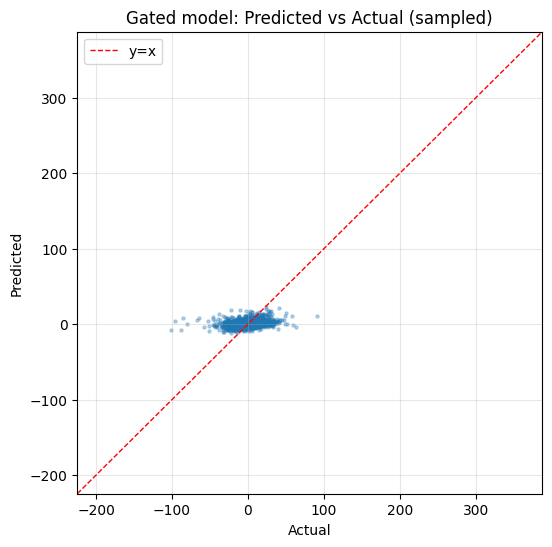

In [13]:
# Visualization: predicted vs actual (gated model)
import matplotlib.pyplot as plt

# Ensure combined_pred/full_y_raw are available from previous cell
y_true = full_y_raw
y_pred = full_pred_raw
# sample to avoid plotting millions of points
sample_n = min(10000, len(y_true))
idx_sample = np.random.default_rng(42).choice(len(y_true), sample_n, replace=False)
plt.figure(figsize=(6, 6))
plt.scatter(y_true[idx_sample], y_pred[idx_sample], s=5, alpha=0.3)
lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
plt.plot(lims, lims, 'r--', linewidth=1, label='y=x')
plt.xlim(lims); plt.ylim(lims)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Gated model: Predicted vs Actual (sampled)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [14]:
y_true,y_pred

(array([-3.529787  ,  0.71048737, -0.50008297, ...,  3.6299229 ,
         4.760027  , -6.530285  ]),
 array([-0.39246419,  1.67577977,  1.59220432, ...,  0.95203473,
         1.15715105, -0.47421065]))